# RSNA Knee MRI — DICOM Viewer

In [1]:
import numpy as np
import pandas as pd
import pydicom
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from pathlib import Path
from ipywidgets import interact, IntSlider, Dropdown, Output
import ipywidgets as widgets
import warnings
warnings.filterwarnings('ignore')

KAGGLE_DIR  = Path('/run/media/mahyar/Samsung-990-PRO/Projects/Kaggle/rsna-knee-abnormality-detection')
PYTHON_DIR  = Path('/run/media/mahyar/Samsung-990-PRO/Projects/Python/RSNA Knee Abnormality Detection')
IMG_DIR     = KAGGLE_DIR / 'train_series'
LABELS_CSV  = PYTHON_DIR / 'train_filled_corrected.csv'
SERIES_CSV  = PYTHON_DIR / 'train_series.csv'

df_labels = pd.read_csv(LABELS_CSV)
df_series = pd.read_csv(SERIES_CSV)
print(f'Studies : {len(df_labels)}')
print(f'Series  : {len(df_series)}')

Studies : 4407
Series  : 24371


In [2]:
LABEL_COLS = ['ACL','MCL','Medial Meniscus','Lateral Meniscus',
              'Medial OA','Lateral OA','PF OA','Effusion',
              'Synovitis',"Baker's",'Contusion','Fracture']

def load_dcm(path: str) -> np.ndarray:
    """Load a DICOM file and return a normalised float32 (H,W) array in [0,1]."""
    dcm       = pydicom.dcmread(path)
    img       = dcm.pixel_array.astype(np.float32)
    slope     = float(getattr(dcm, 'RescaleSlope',     1.0))
    intercept = float(getattr(dcm, 'RescaleIntercept', 0.0))
    img       = img * slope + intercept
    p2, p98   = np.percentile(img, 2), np.percentile(img, 98)
    denom     = p98 - p2
    return ((img - p2) / denom if denom > 0 else np.zeros_like(img)).astype(np.float32)

def get_series_dcm_files(study_uid: str, series_uid: str):
    path = IMG_DIR / study_uid / series_uid
    return sorted(path.glob('*.dcm'))

def positive_labels(study_uid: str):
    row = df_labels[df_labels['StudyInstanceUID'] == study_uid]
    if row.empty:
        return []
    return [l for l in LABEL_COLS if row.iloc[0][l] == 1]

print('Utilities loaded.')

Utilities loaded.


## 1 — Browse all slices of a series (interactive slider)

In [3]:
# ── Pick a study & series ─────────────────────────────────────────────────────
STUDY_IDX  = 0   # ← change to browse different studies (0 … len(df_labels)-1)
SERIES_IDX = 0   # ← change to pick a different series within that study

study_uid  = df_labels.iloc[STUDY_IDX]['StudyInstanceUID']
study_rows = df_series[df_series['StudyInstanceUID'] == study_uid]
series_row = study_rows.iloc[SERIES_IDX]
series_uid = series_row['SeriesInstanceUID']
dcm_files  = get_series_dcm_files(study_uid, series_uid)

pos_lbl    = positive_labels(study_uid)
plane      = series_row['Anatomical_Plane']
fluid      = series_row['Fluid_Sensitive']
fat        = series_row['Fat_Suppression']

print(f'Study  {STUDY_IDX}: {study_uid}')
print(f'Series {SERIES_IDX}: {series_uid}')
print(f'Plane={plane}  Fluid_Sensitive={fluid}  Fat_Suppression={fat}')
print(f'Slices: {len(dcm_files)}')
print(f'Positive labels: {pos_lbl if pos_lbl else "none"}')

out = Output()

def show_slice(slice_idx):
    with out:
        out.clear_output(wait=True)
        img = load_dcm(str(dcm_files[slice_idx]))
        fig, ax = plt.subplots(1, 1, figsize=(6, 6))
        ax.imshow(img, cmap='gray', vmin=0, vmax=1)
        ax.set_title(f'Slice {slice_idx+1}/{len(dcm_files)}  —  {plane}',
                     fontsize=12)
        ax.axis('off')
        plt.tight_layout()
        plt.show()

slider = IntSlider(value=0, min=0, max=len(dcm_files)-1,
                   description='Slice', continuous_update=False)
widgets.interactive_output(show_slice, {'slice_idx': slider})
display(slider, out)
show_slice(0)

Study  0: 1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260
Series 0: 1.2.826.0.1.3680043.8.498.12343110195036213483454091715412333772
Plane=Sagittal  Fluid_Sensitive=1  Fat_Suppression=1
Slices: 22
Positive labels: ['Medial Meniscus', 'Effusion']


IntSlider(value=0, continuous_update=False, description='Slice', max=21)

Output()

## 2 — Show all slices of a series as a grid

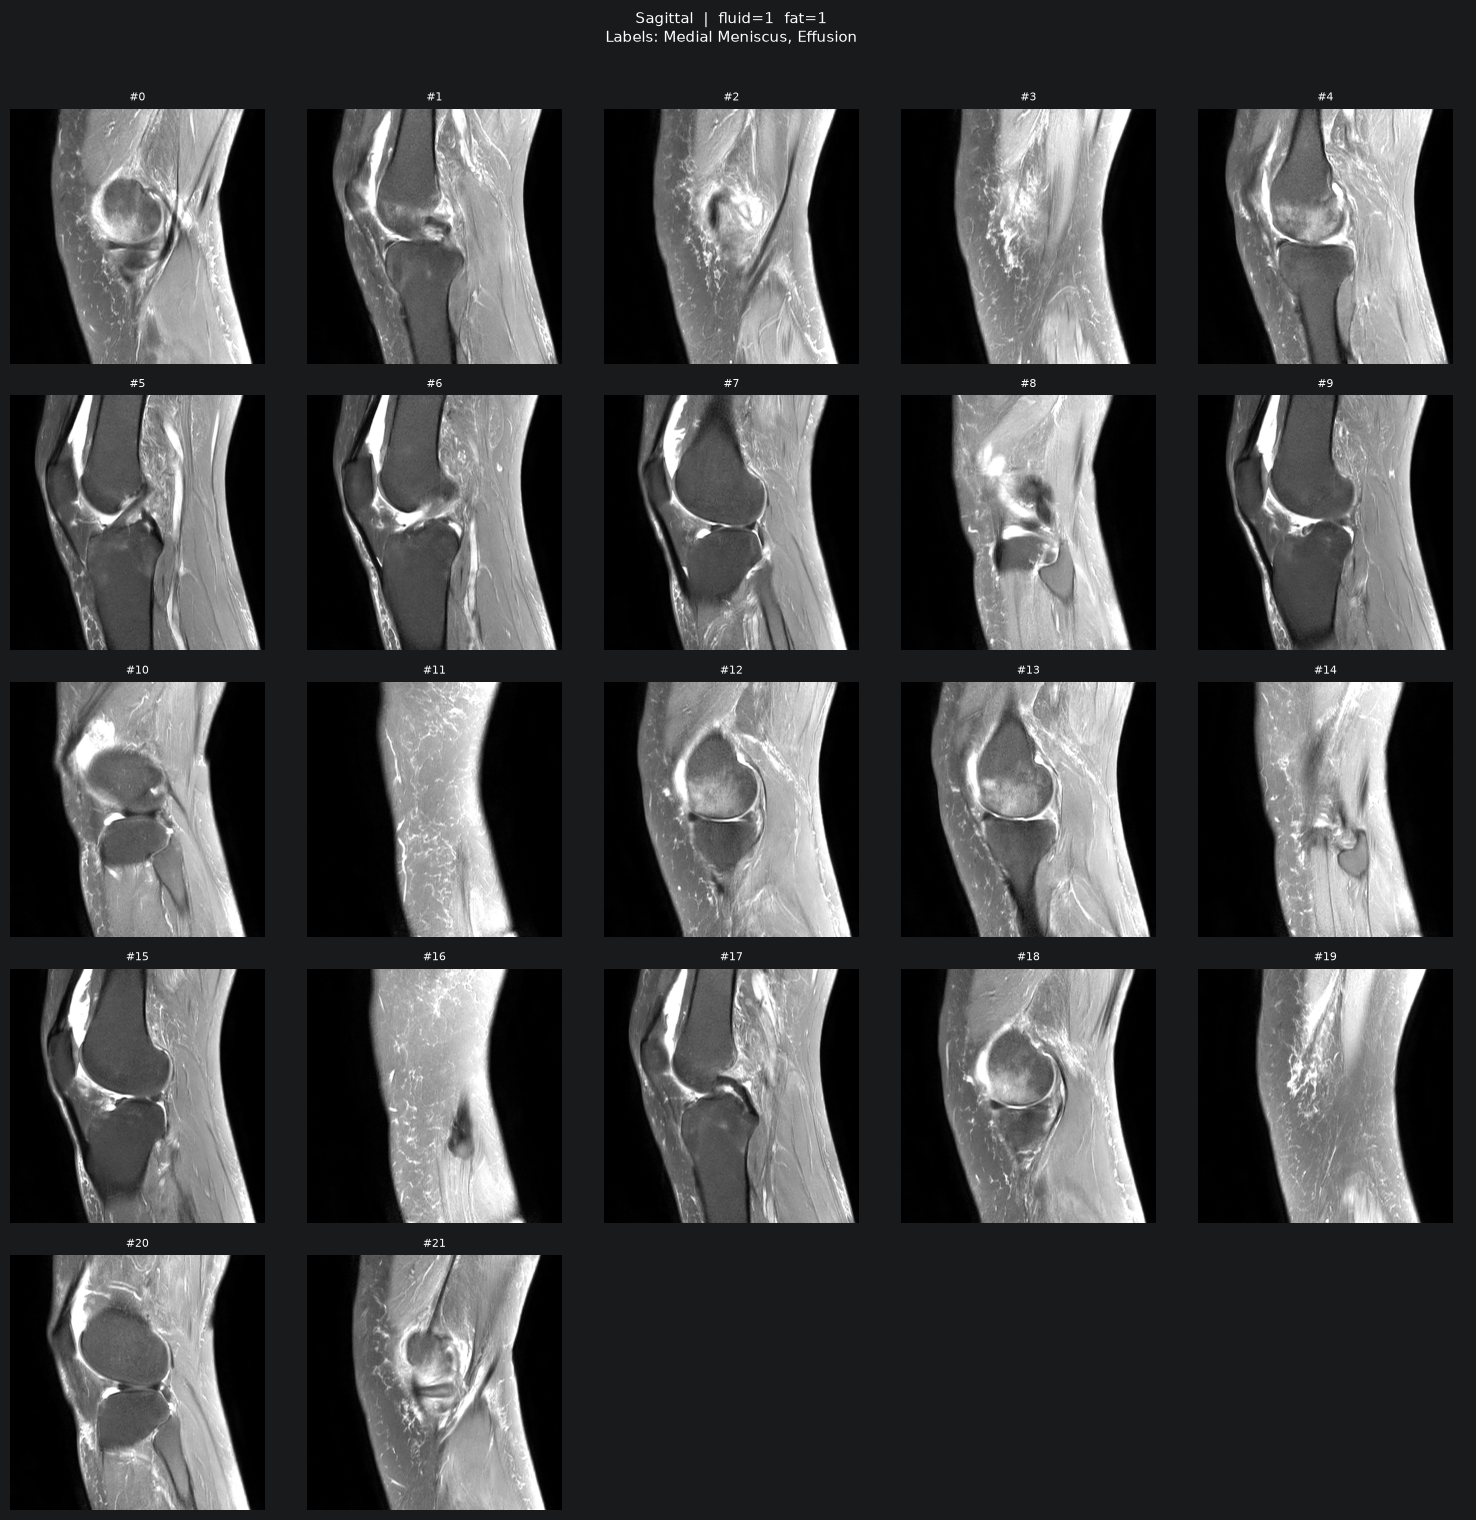

Resolution: (512, 512)


In [4]:
# Re-uses the STUDY_IDX / SERIES_IDX set in cell above.
# Evenly samples up to MAX_SHOW slices so the grid fits on screen.
MAX_SHOW = 25

n        = len(dcm_files)
indices  = np.linspace(0, n-1, min(MAX_SHOW, n), dtype=int)
cols     = 5
rows     = int(np.ceil(len(indices) / cols))

fig, axes = plt.subplots(rows, cols, figsize=(cols*3, rows*3))
axes = axes.flatten()

for i, idx in enumerate(indices):
    img = load_dcm(str(dcm_files[idx]))
    axes[i].imshow(img, cmap='gray', vmin=0, vmax=1)
    axes[i].set_title(f'#{idx}', fontsize=8)
    axes[i].axis('off')

for j in range(len(indices), len(axes)):
    axes[j].axis('off')

plt.suptitle(
    f'{plane}  |  fluid={fluid}  fat={fat}\n'
    f'Labels: {", ".join(pos_lbl) if pos_lbl else "none"}',
    fontsize=11, y=1.01)
plt.tight_layout()
plt.show()
print(f'Resolution: {load_dcm(str(dcm_files[0])).shape}')

## 3 — Compare all series of one study side by side (middle slice)

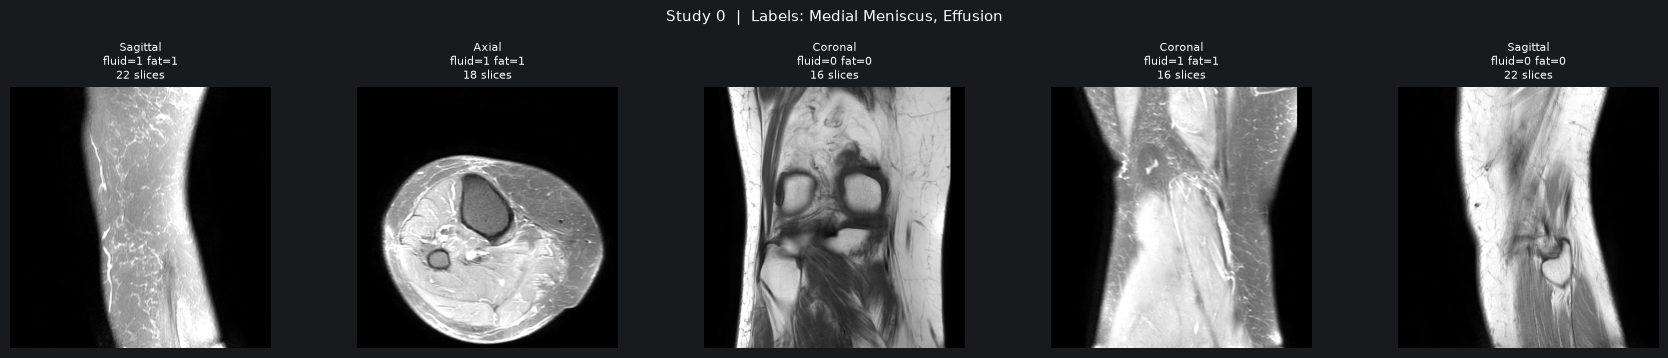

In [5]:
# Shows the middle slice of every series for the chosen study.
study_rows = df_series[df_series['StudyInstanceUID'] == study_uid]
n_series   = len(study_rows)
cols       = min(5, n_series)
rows       = int(np.ceil(n_series / cols))

fig, axes = plt.subplots(rows, cols, figsize=(cols*3.5, rows*3.5))
axes = np.array(axes).flatten() if n_series > 1 else [axes]

for i, (_, srow) in enumerate(study_rows.iterrows()):
    files = get_series_dcm_files(study_uid, srow['SeriesInstanceUID'])
    if not files:
        axes[i].set_title('no files', fontsize=8); axes[i].axis('off'); continue
    mid   = files[len(files)//2]
    img   = load_dcm(str(mid))
    axes[i].imshow(img, cmap='gray', vmin=0, vmax=1)
    axes[i].set_title(
        f"{srow['Anatomical_Plane']}\nfluid={srow['Fluid_Sensitive']} fat={srow['Fat_Suppression']}\n{len(files)} slices",
        fontsize=8)
    axes[i].axis('off')

for j in range(n_series, len(axes)):
    axes[j].axis('off')

plt.suptitle(
    f'Study {STUDY_IDX}  |  Labels: {", ".join(pos_lbl) if pos_lbl else "none"}',
    fontsize=11, y=1.01)
plt.tight_layout()
plt.show()

## 4 — Overlapping patch visualisation (what the model sees)

Native: 512×512  →  padded: 560×560  →  4×4 = 16 patches


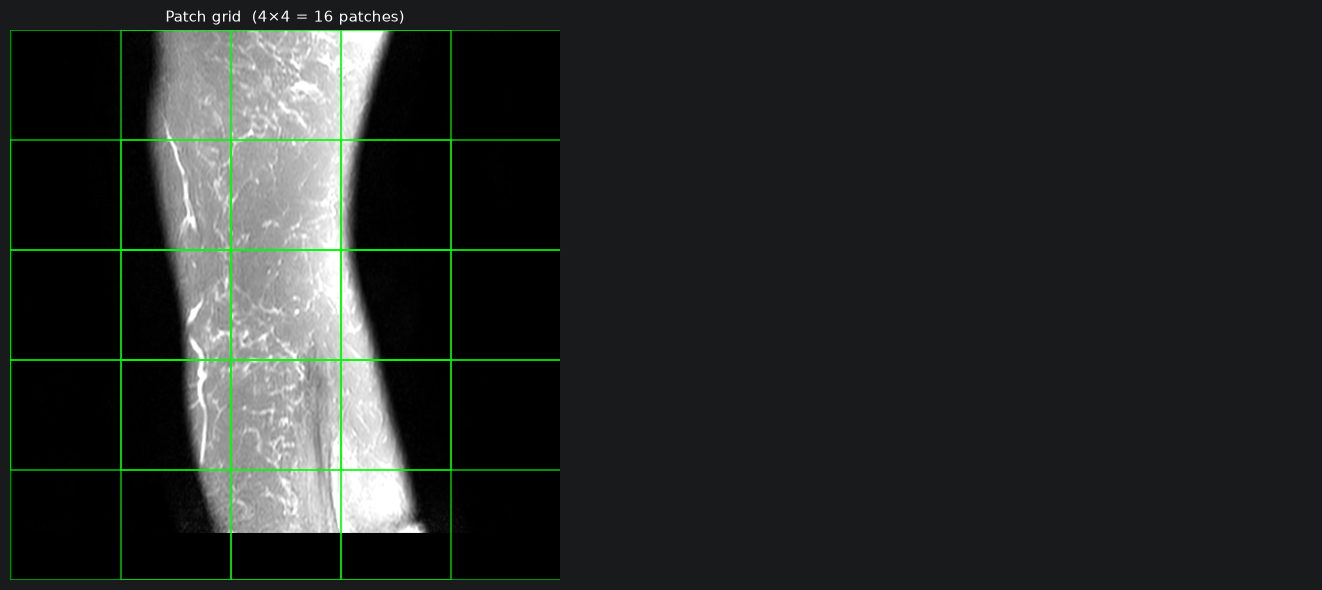

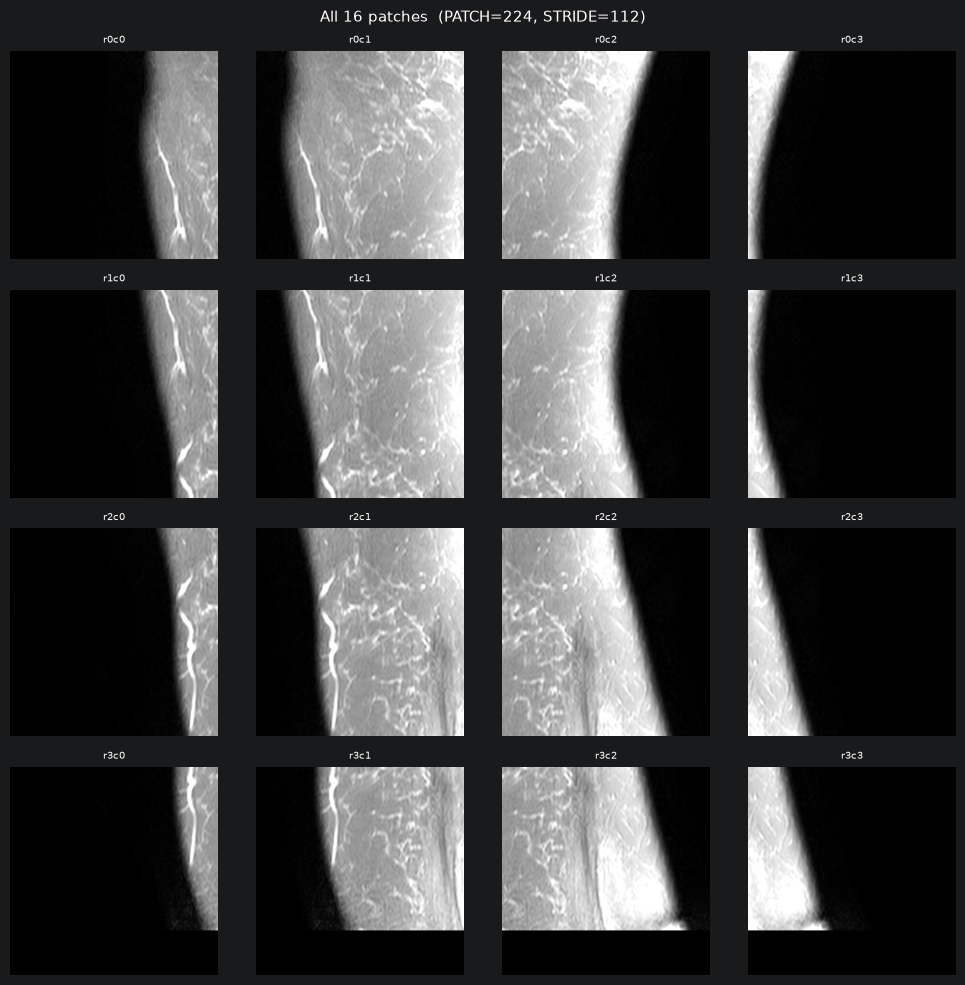

In [6]:
PATCH_SIZE   = 224
PATCH_STRIDE = 112

def compute_valid_size(H, W, patch=224, stride=112):
    def _next(s):
        if s < patch: return patch
        rem = (s - patch) % stride
        return s if rem == 0 else s + (stride - rem)
    return _next(H), _next(W)

# Load the middle slice of the currently selected series
mid_file = dcm_files[len(dcm_files)//2]
raw_img  = load_dcm(str(mid_file))         # (H, W)

# Halve if >512
import cv2
H, W = raw_img.shape
proc_H = H // 2 if H > 512 else H
proc_W = W // 2 if W > 512 else W
if proc_H != H or proc_W != W:
    raw_img = cv2.resize(raw_img, (proc_W, proc_H), interpolation=cv2.INTER_AREA)

H, W     = raw_img.shape
vH, vW   = compute_valid_size(H, W)

# Pad image (right + bottom)
padded   = np.zeros((vH, vW), dtype=np.float32)
padded[:H, :W] = raw_img

# Compute patch grid
ys = list(range(0, vH - PATCH_SIZE + 1, PATCH_STRIDE))
xs = list(range(0, vW - PATCH_SIZE + 1, PATCH_STRIDE))
n_patches = len(ys) * len(xs)

print(f'Native: {H}×{W}  →  padded: {vH}×{vW}  →  {len(ys)}×{len(xs)} = {n_patches} patches')

# ── Figure 1: image with patch grid overlay ─────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(padded, cmap='gray', vmin=0, vmax=1)
for y in ys:
    for x in xs:
        rect = plt.Rectangle((x, y), PATCH_SIZE, PATCH_SIZE,
                              edgecolor='lime', facecolor='none', lw=1.2, alpha=0.7)
        axes[0].add_patch(rect)
axes[0].set_title(f'Patch grid  ({len(ys)}×{len(xs)} = {n_patches} patches)', fontsize=11)
axes[0].axis('off')

# ── Figure 2: all individual patches ────────────────────────────────────────
cols_p = len(xs)
rows_p = len(ys)
ax2    = axes[1]
ax2.axis('off')

plt.tight_layout()
plt.show()

# Show each patch individually
fig2, axes2 = plt.subplots(rows_p, cols_p,
                            figsize=(cols_p*2.5, rows_p*2.5))
if n_patches == 1:
    axes2 = np.array([[axes2]])
elif rows_p == 1:
    axes2 = axes2[np.newaxis, :]
elif cols_p == 1:
    axes2 = axes2[:, np.newaxis]

for ri, y in enumerate(ys):
    for ci, x in enumerate(xs):
        patch = padded[y:y+PATCH_SIZE, x:x+PATCH_SIZE]
        axes2[ri, ci].imshow(patch, cmap='gray', vmin=0, vmax=1)
        axes2[ri, ci].set_title(f'r{ri}c{ci}', fontsize=7)
        axes2[ri, ci].axis('off')

plt.suptitle(f'All {n_patches} patches  (PATCH={PATCH_SIZE}, STRIDE={PATCH_STRIDE})',
             fontsize=11)
plt.tight_layout()
plt.show()

## 5 — Search studies by label

Found 1301 studies with ['ACL']. Showing first 6.


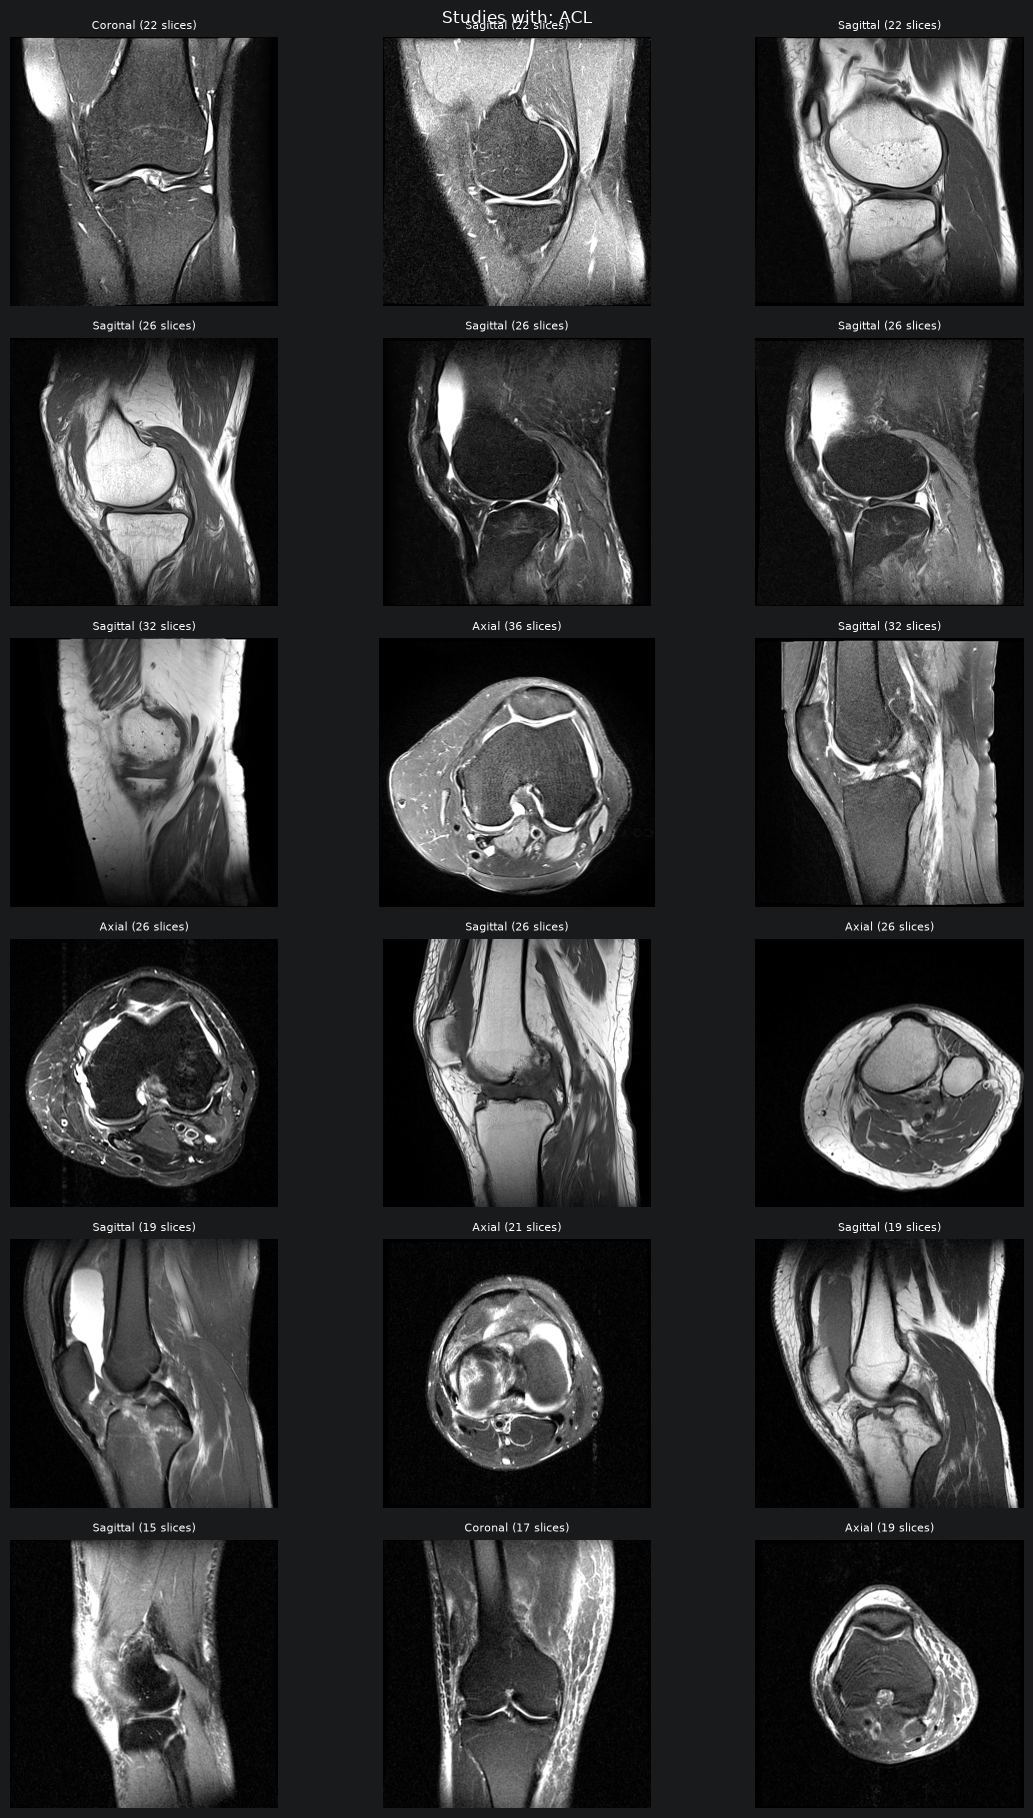

In [7]:
# Set the labels you want to filter by (all must be positive).
# Example: FIND_LABELS = ['ACL', 'Effusion']
FIND_LABELS = ['ACL']
MAX_RESULTS = 6

mask = np.ones(len(df_labels), dtype=bool)
for lbl in FIND_LABELS:
    mask &= (df_labels[lbl] == 1)

hits = df_labels[mask].head(MAX_RESULTS)
print(f'Found {mask.sum()} studies with {FIND_LABELS}. Showing first {len(hits)}.')

fig, axes = plt.subplots(len(hits), 3, figsize=(12, len(hits)*3 + 0.5))
if len(hits) == 1:
    axes = axes[np.newaxis, :]

for row_i, (_, study_row) in enumerate(hits.iterrows()):
    s_uid   = study_row['StudyInstanceUID']
    series  = df_series[df_series['StudyInstanceUID'] == s_uid]
    pos     = [l for l in LABEL_COLS if study_row[l] == 1]

    for col_i in range(3):
        ax = axes[row_i, col_i]
        if col_i >= len(series):
            ax.axis('off'); continue
        srow   = series.iloc[col_i]
        files  = get_series_dcm_files(s_uid, srow['SeriesInstanceUID'])
        if not files:
            ax.axis('off'); continue
        img    = load_dcm(str(files[len(files)//2]))
        ax.imshow(img, cmap='gray', vmin=0, vmax=1)
        ax.set_title(
            f"{srow['Anatomical_Plane']} ({len(files)} slices)",
            fontsize=8)
        ax.axis('off')
        if col_i == 0:
            ax.set_ylabel(f'Study {row_i}\n{", ".join(pos[:4])}', fontsize=7)

plt.suptitle(f'Studies with: {", ".join(FIND_LABELS)}', fontsize=12)
plt.tight_layout()
plt.show()

## 6 — Dataset statistics

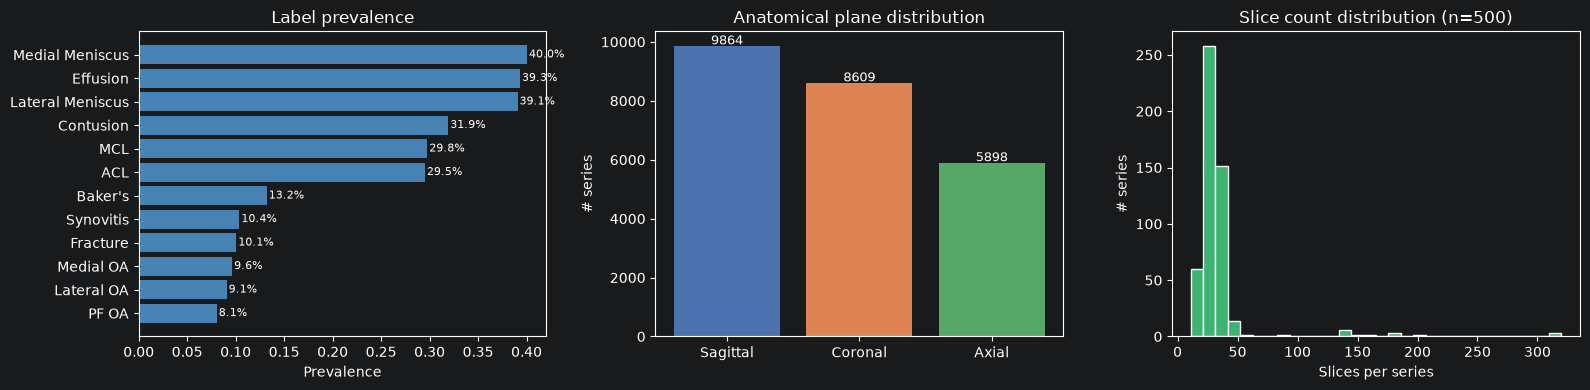

Slice counts — min=11  median=30  max=320


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Label prevalence
prev = df_labels[LABEL_COLS].mean().sort_values()
axes[0].barh(prev.index, prev.values, color='steelblue')
axes[0].set_xlabel('Prevalence')
axes[0].set_title('Label prevalence')
for v, name in zip(prev.values, prev.index):
    axes[0].text(v + 0.002, name, f'{v:.1%}', va='center', fontsize=8)

# Anatomical plane distribution
plane_counts = df_series['Anatomical_Plane'].value_counts()
axes[1].bar(plane_counts.index, plane_counts.values, color=['#4C72B0','#DD8452','#55A868'])
axes[1].set_title('Anatomical plane distribution')
axes[1].set_ylabel('# series')
for i, (name, val) in enumerate(plane_counts.items()):
    axes[1].text(i, val + 50, str(val), ha='center', fontsize=9)

# Slices per series (sample 500)
sample_series = df_series.sample(min(500, len(df_series)), random_state=42)
slice_counts  = []
for _, row in sample_series.iterrows():
    p = IMG_DIR / row['StudyInstanceUID'] / row['SeriesInstanceUID']
    if p.exists():
        slice_counts.append(len(list(p.glob('*.dcm'))))
axes[2].hist(slice_counts, bins=30, color='mediumseagreen', edgecolor='white')
axes[2].set_xlabel('Slices per series')
axes[2].set_title(f'Slice count distribution (n={len(slice_counts)})')
axes[2].set_ylabel('# series')

plt.tight_layout()
plt.show()

print(f'Slice counts — min={min(slice_counts)}  median={int(np.median(slice_counts))}  max={max(slice_counts)}')